# Experiências de comunicação com e sem SA

In [ ]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent: root=root.parent
sys.path.insert(0,str(root))

# Comunicação e PR-AUC — Fedavg

**Comparação emparelhada com/sem SA dentro de cada abordagem.** Mesmos IDs, cinco seeds (2031–2035), três rondas e dez épocas locais. 22 clientes, pesos de fit: 72,73% Icentia e 27,27% PhysioNet. Sem desistências nesta comparação. SA: soma única, 24 bits, limiar 12. FedAvg usa CNN1D comum; Soft Labels usa professores AE+CNN/MobileNetV2 e aluno CNN1D. A diferença entre abordagens inclui arquitetura/objetivo e custo de treino distintos; as épocas iguais não igualam FLOPs.

{'status': 'complete', 'validated_runs': 20, 'signature': '590f95d2e0ae0804092eeab9326543fffa70e3b18e6d11584e39f0b18bdacb98'}

**20/20 execuções concluídas e validadas.** Barras parciais só incluem execuções completas; `n` indica seeds disponíveis.

PR-AUC local: professor no próprio holdout nas Soft Labels; rede local após treino, antes da agregação, em FedAvg. PR-AUC global: o modelo global avaliado nos mesmos holdouts. Média ponderada dos AP individuais, não uma curva conjunta. O modelo FedAvg entregue ao cliente após agregação corresponde à barra global. Dev é secundário e está nas tabelas por cliente; test não é usado. AP indefinida num holdout com uma só classe é excluída, com cobertura explícita nas tabelas.

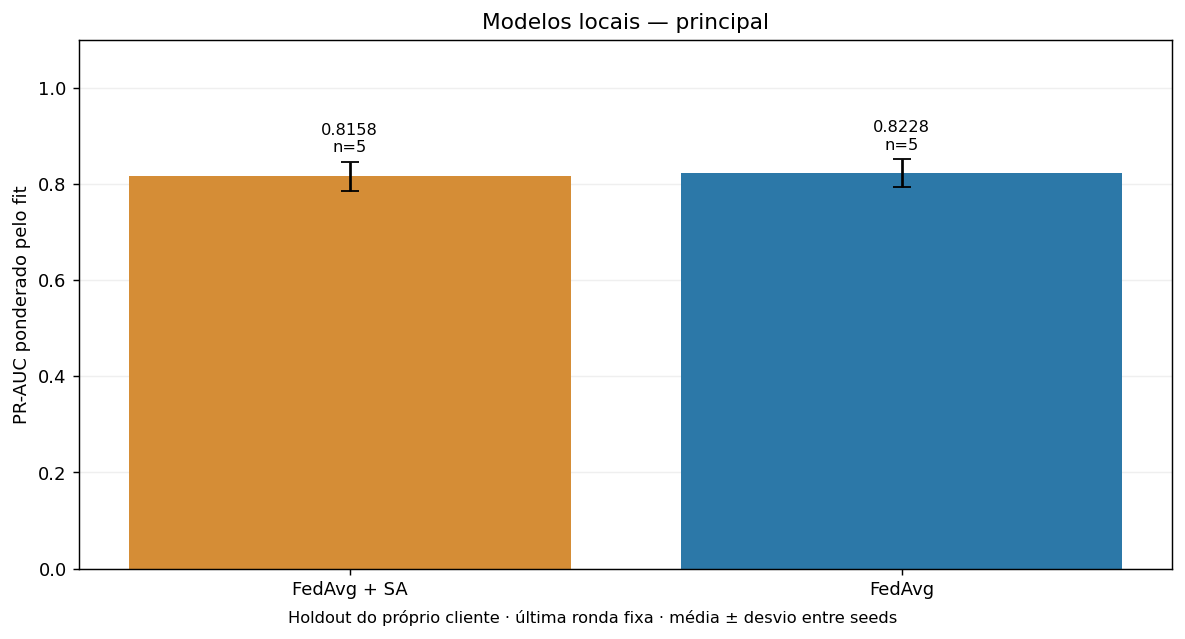

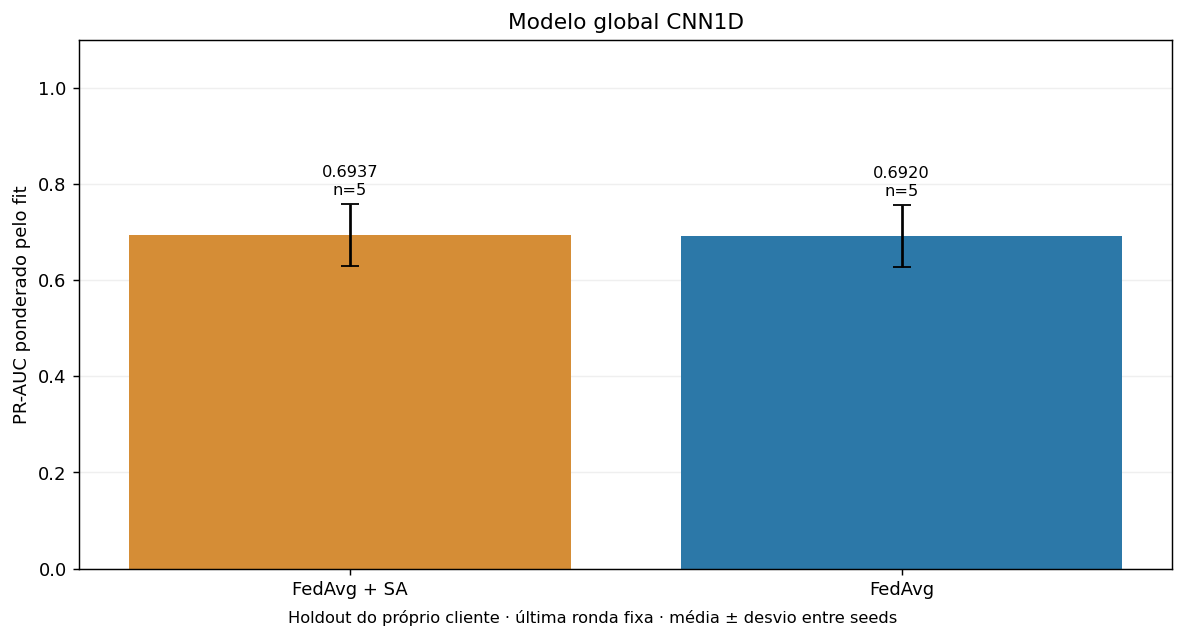

algorithm,condition,seed,role,pr_auc_ap,roc_auc,recall,far,f1,valid_ap_clients,total_clients,ap_fit_coverage
Fedavg,SA,2031,global,0.727394,0.764464,0.290210,0.274194,0.182828,22,22,1.0
Fedavg,SA,2031,local,0.860756,0.883316,0.733204,0.135852,0.654203,22,22,1.0
Fedavg,SA,2032,global,0.730543,0.801078,0.276224,0.274194,0.164069,22,22,1.0
Fedavg,SA,2032,local,0.779755,0.859246,0.763299,0.164325,0.708451,22,22,1.0
Fedavg,SA,2033,global,0.580844,0.682743,0.272727,0.270335,0.158173,22,22,1.0
Fedavg,SA,2033,local,0.800281,0.874612,0.742632,0.174419,0.624778,22,22,1.0
Fedavg,SA,2034,global,0.701986,0.790911,0.395979,0.274348,0.290673,22,22,1.0
Fedavg,SA,2034,local,0.809161,0.864540,0.733142,0.126346,0.689620,22,22,1.0
Fedavg,SA,2035,global,0.727918,0.814865,0.272727,0.270335,0.158173,22,22,1.0
Fedavg,SA,2035,local,0.828837,0.874964,0.731831,0.103813,0.688946,22,22,1.0


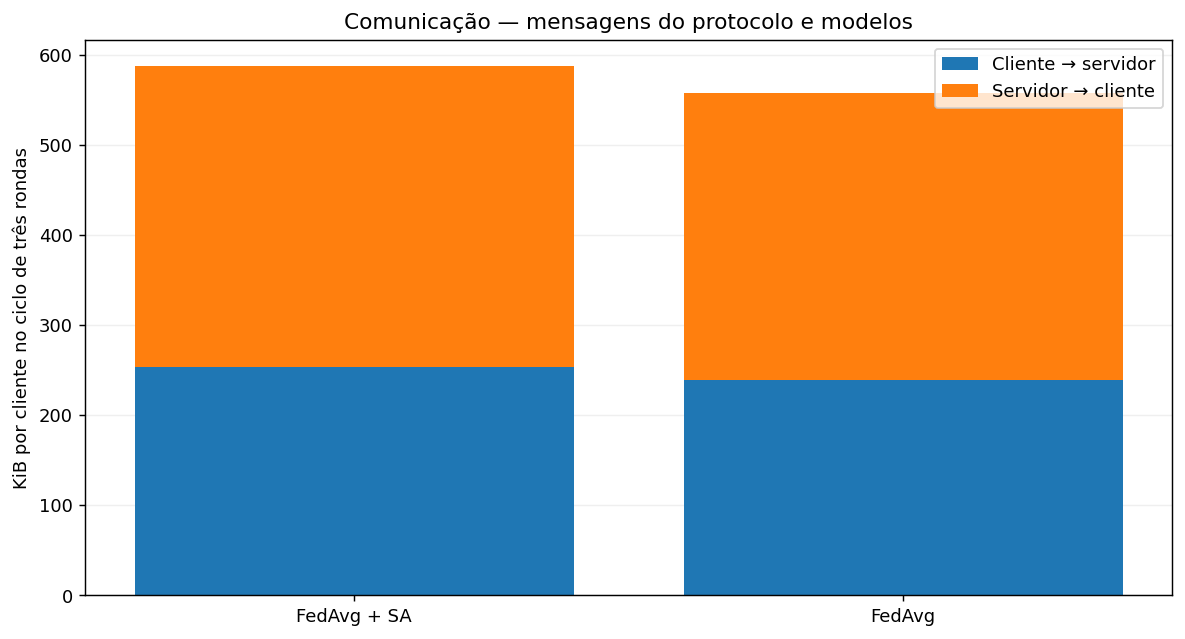

algorithm,condition,seed,upload_bytes,download_bytes,total_bytes,aggregation_seconds,local_compute_seconds
Fedavg,SA,2031,5720088,7509920,13230008,4.235094,23.838401
Fedavg,SA,2032,5720088,7509920,13230008,6.205324,34.948589
Fedavg,SA,2033,5720088,7509920,13230008,4.406528,24.905172
Fedavg,SA,2034,5720088,7509920,13230008,4.180660,22.515737
Fedavg,SA,2035,5720088,7509920,13230008,9.928714,60.105515
Fedavg,plain,2031,5387184,7182560,12569744,0.000464,24.492564
Fedavg,plain,2032,5387184,7182560,12569744,0.000680,33.012817
Fedavg,plain,2033,5387184,7182560,12569744,0.000508,26.301538
Fedavg,plain,2034,5387184,7182560,12569744,0.000475,24.001517
Fedavg,plain,2035,5387184,7182560,12569744,0.000781,43.316742


condition,algorithm,seed,role,SA,plain,SA_minus_plain
,Fedavg,2031,global,0.727394,0.727698,-0.000303
,Fedavg,2031,local,0.860756,0.861118,-0.000362
,Fedavg,2032,global,0.730543,0.731184,-0.000641
,Fedavg,2032,local,0.779755,0.780141,-0.000387
,Fedavg,2033,global,0.580844,0.580707,0.000136
,Fedavg,2033,local,0.800281,0.822191,-0.021910
,Fedavg,2034,global,0.701986,0.693174,0.008812
,Fedavg,2034,local,0.809161,0.822075,-0.012914
,Fedavg,2035,global,0.727918,0.727114,0.000804
,Fedavg,2035,local,0.828837,0.828287,0.000550


Comunicação: soma dos payloads de upload e download; inclui chaves, partilhas e desmascaramento da SA, distribuição inicial e três distribuições globais (uma após cada ronda). Contagem por mensagem lógica, sem cabeçalhos TCP/TLS nem retransmissões. Âncoras sintéticas geradas localmente; preparação inicial dos dados não contabilizada. Tempos medidos localmente, sem latência de rede. FedAvg: parâmetros com sinal codificados por transformação afim com limite público ±256, sem clipping silencioso; buffers inteiros são arredondados. Soft Labels: probabilidades ponderadas em [0,1]. Os 24 bits não representam o mesmo erro absoluto nos dois espaços. SA não oferece LDP nem esta simulação constitui uma validação de segurança para produção.

In [1]:
from support.sa_communication_report import render
render('Fedavg')